### Frühsport – Lösung Schritt für Schritt

*31. Bundeswettbewerb Informatik (2012), 1. Runde, Aufgabe 1*

Die BWINF-Schlange Digitail wacht nach einer durchrechneten Nacht mit heißen Algorhythmen und zuviel Soft Ware ganz verknäult auf und möchte wieder ihr altes geradliniges Selbst werden. „Wie gut, dass ich in einer zwei- und nicht dreidimensionalen Welt lebe“, denkt sie, „denn sonst könnte ich echt ein Problem haben“. Auch so braucht sie aber deine Hilfe, sich zu entknäulen.

Digitail besteht aus geraden Ringeln der Länge 1, die Gitterpunkte mit ganzzahligen Koordinaten verbinden. Sie ist normalerweise goldfarben; aber sie kann sich vorübergehend strecken und wird dann stellenweise rot: Aus einem oder zwei aufeinander folgenden goldenen Ringeln können doppelt so viele rote Ringel werden. Wenn sich die Schlange wieder zusammenzieht, werden aus zwei oder vier aufeinander folgenden roten Ringeln halb so viele goldene Ringel. Außerdem kann die Schlange ein oder zwei aufeinander folgende Ringel beliebiger Farbe verschieben, und zwei aufeinander folgende Ringel können ihre Farben tauschen. Diese akrobatischen Übungen sind allerdings alle nur möglich, wenn die dafür benötigten Gitterpunkte vorher frei waren und die Schlange zusammenhängend bleibt.

#### Aufgabe 1

Schreibe ein Programm, das eine beliebig verknäulte anfangs goldene Schlange einliest und eine Folge von Schritten der beschriebenen Art berechnet, nach deren Ausführung alle Ringel der Schlange auf einer Geraden liegen und (wieder) golden sind. Visualisiere die Ausführung der Schritte so, dass man sehen kann, wie sich die Schlange entknäult.

**Zu den Daten:** Beispieldaten gibt es zu dieser Aufgabe nicht, das Eingabeformat darf man selbst wählen. Wir lesen eine Datei, die den Weg der Schlange von ihrem Anfang aus beschreibt: `R` rechts, `L` links, `O` oben, `U` unten (ein Buchstabe je Ringel, Zeilen mit `#` am Anfang sind Kommentare). In `eigene_testdaten/` liegen vier solche Dateien: `spirale.txt` (42 Ringel, ein Ende liegt außen), `knaeuel_4x4.txt`, `knaeuel_6x6.txt` und `knaeuel_8x8.txt` (dichte Knäuel mit 15, 35 und 63 Ringeln, die jeweils ein ganzes Feld ausfüllen und bei denen **beide Enden innen** liegen; sie sind mit zufälligen „Backbite“-Zügen erzeugt, also nicht handgemacht).

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Darstellung wählen:** Die Schlange speichern wir als Liste ihrer **Gitterpunkte** (zwei aufeinander folgende Punkte sind Nachbarn). Die Ringel sind die Strecken dazwischen. Das ist handlicher als eine Liste von Strecken, bei der man waagerechte und senkrechte Ringel getrennt behandeln müsste.
- **Fallunterscheidung:** Liegt ein Ende der Schlange „außen“, ist das Entknäulen leicht (Fall 1). Sonst machen wir zuerst eines der Enden zu einem äußeren Ende (Fall 2).
- **Invariante:** Aus einem goldenen Ringel werden zwei rote und umgekehrt. Zählt man ein goldenes Ringel wie zwei rote, bleibt die Summe immer gleich. Damit kann die Schlange nie kürzer als ihre Anfangslänge `n` und nie länger als `2n` Ringel werden.
- **Greedy beim Farbentauschen:** Für jeden Schritt brauchen wir bestimmte Farben an bestimmten Stellen. Wir tauschen so wenig wie möglich, indem wir die Ringel mit der richtigen Farbe nehmen, die am nächsten liegen.

**Nützliche Funktionen**
- Vergleich von Tupeln: Python vergleicht `(3, 5)` und `(3, 7)` zuerst nach der ersten, bei Gleichstand nach der zweiten Zahl.
- `list.index(x)`, `list.insert`, `list.pop`, Slices wie `p[i + 1:i + 2] = neu`: damit ändern wir die Punktliste.
- `matplotlib.pyplot` (`plot`, `subplots`) für die Zeichnung der Schlange.

## Die Idee in Worten

**Was die Schritte geometrisch bedeuten.** Die Aufgabe sagt nicht genau, wie ein Ringel „zu zwei roten“ wird. Wir legen es so fest (die Hinweise gehen von derselben Vorstellung aus: die Schlange hat zwischen `n` und `2n` Ringel):

- **Strecken am Ende:** Das letzte Ringel (golden) wird zu zwei roten. Die Spitze der Schlange rückt dabei um einen Gitterpunkt weiter, auf einen freien Nachbarpunkt. Die Schlange wird um einen Ringel länger.
- **Zusammenziehen am Ende:** Zwei rote Ringel am Ende werden zu einem goldenen. Die Spitze zieht sich um einen Punkt zurück, die Schlange wird um einen Ringel kürzer.
- **Ausbuchten in der Mitte:** Zwei aufeinander folgende goldene Ringel von `a` über `b` nach `c` werden zu vier roten, die ebenfalls von `a` nach `c` führen, aber über drei freie Punkte. (Ein einzelnes Ringel in der Mitte kann man nicht verdoppeln, ohne dass die Punkte `a` und `c` auseinanderrücken. Mit zwei Ringeln geht es, denn der Weg hat dann wieder gerade Länge.)
- **Tauschen:** Zwei benachbarte Ringel tauschen die Farben. Die Geometrie ändert sich nicht.
- Den Schritt **Verschieben** brauchen wir nicht, die Ausbuchtung leistet dasselbe. Zusammenziehen in der Mitte brauchen wir auch nicht.

**Fall 1: Eine Spitze liegt außen.** „Außen“ heißt: Von der Spitze aus führt ein Strahl in eine der vier Richtungen, auf dem kein Punkt der Schlange liegt. Dann strecken wir die Spitze `n`-mal in diese Richtung (die Schlange hat jetzt `2n` Ringel), danach zieht sich das **andere** Ende `n`-mal zusammen. Es bleibt der gerade Teil übrig, der aus dem Knäuel herausgestreckt wurde. Er hat `n` Ringel und ist golden.

**Fall 2: Beide Enden stecken im Knäuel.** Wir nehmen eine Richtung `r` und die Ecke `Q`, die in dieser Richtung am weitesten außen liegt. `Q` ist keine Spitze (sonst wären wir in Fall 1). Ihre beiden Nachbarn liegen links von ihr und unter ihr (bezogen auf `r`). Sei `d` die Anzahl der Ringel von `Q` bis zur näheren Spitze. Dann
1. buchten wir `Q` genau `d`-mal nach außen aus (jedes Mal wird die Ecke um einen Punkt nach außen geschoben, die Schlange wird um 2 Ringel länger),
2. ziehen die nähere Spitze `2d`-mal zusammen. Jetzt ist die ausgebuchtete Ecke selbst die Spitze und liegt ganz außen.

Danach geht es mit Fall 1 weiter. Die Länge bleibt dabei zwischen `n` und `n + 2d` Ringeln, wegen `d ≤ n/2` also höchstens `2n`.

**Farben.** Für jeden Schritt müssen die richtigen Ringel die richtige Farbe haben (golden vor dem Strecken, rot vor dem Zusammenziehen). Das Programm besorgt sich vorher die Farbe durch Tauschen benachbarter Ringel.

## Schritt 1: Die Schlange einlesen

Eine Zeile wie `RROU` heißt: zweimal rechts, einmal oben, einmal unten. Wir starten bei `(0, 0)` und hängen für jeden Buchstaben den nächsten Punkt an. Wer sich selbst kreuzt, ist keine gültige Schlange.

In [ ]:
RICHTUNG = {'R': (1, 0), 'L': (-1, 0), 'O': (0, 1), 'U': (0, -1)}


def punkte_aus_richtungen(text):
    """'RROU' -> Liste der Gitterpunkte, beginnend bei (0, 0)"""
    punkte = [(0, 0)]
    for zeichen in text.strip():
        dx, dy = RICHTUNG[zeichen]
        x, y = punkte[-1]
        punkte.append((x + dx, y + dy))
    return punkte


def lies_schlange(dateiname):
    with open(dateiname, encoding='utf-8') as f:
        text = ''.join(zeile.strip() for zeile in f if not zeile.startswith('#'))
    punkte = punkte_aus_richtungen(text)
    if len(set(punkte)) != len(punkte):
        raise ValueError('Die Schlange kreuzt sich selbst')
    return punkte


print(punkte_aus_richtungen('RROU'))
knaeuel = lies_schlange('eigene_testdaten/knaeuel_4x4.txt')
print(len(knaeuel) - 1, 'Ringel')
print(knaeuel)

[(0, 0), (1, 0), (2, 0), (2, 1), (2, 0)]
15 Ringel
[(0, 0), (-1, 0), (-1, 1), (-1, 2), (-2, 2), (-2, 1), (-2, 0), (-2, -1), (-1, -1), (0, -1), (1, -1), (1, 0), (1, 1), (1, 2), (0, 2), (0, 1)]


## Schritt 2: Zeichnen

Wir zeichnen jedes Ringel als Strecke in seiner Farbe (golden oder rot). Der Anfang der Schlange ist ein Kreis, das Ende ein Quadrat. `zeige_bilder` setzt mehrere Zustände nebeneinander, alle im selben Ausschnitt, damit man die Bewegung sieht.

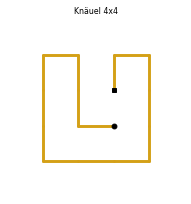

In [ ]:
import matplotlib.pyplot as plt

FARBE = {'g': '#d4a017', 'r': '#c0392b'}


def zeichne(achse, punkte, farben, titel=''):
    for k in range(len(farben)):
        (x1, y1), (x2, y2) = punkte[k], punkte[k + 1]
        achse.plot([x1, x2], [y1, y2], color=FARBE[farben[k]], lw=3, solid_capstyle='round')
    achse.plot(punkte[0][0], punkte[0][1], 'o', color='black', ms=5)       # Anfang
    achse.plot(punkte[-1][0], punkte[-1][1], 's', color='black', ms=5)     # Ende
    achse.set_aspect('equal')
    achse.set_title(titel, fontsize=8)
    achse.axis('off')


def zeige_bilder(bilder, spalten=4):
    """bilder: Liste von (Titel, Punkte, Farben)"""
    alle = [q for (_, p, _) in bilder for q in p]
    xmin, xmax = min(q[0] for q in alle) - 1, max(q[0] for q in alle) + 1
    ymin, ymax = min(q[1] for q in alle) - 1, max(q[1] for q in alle) + 1
    zeilen = (len(bilder) + spalten - 1) // spalten
    fig, achsen = plt.subplots(zeilen, spalten, figsize=(3 * spalten, 3 * zeilen), squeeze=False)
    for k in range(zeilen * spalten):
        achse = achsen[k // spalten][k % spalten]
        if k < len(bilder):
            titel, p, f = bilder[k]
            zeichne(achse, p, f, titel)
            achse.set_xlim(xmin, xmax)
            achse.set_ylim(ymin, ymax)
        else:
            achse.axis('off')
    plt.tight_layout()
    plt.show()


zeige_bilder([('Knäuel 4x4', knaeuel, ['g'] * 15)], spalten=1)

Beide Enden (Kreis und Quadrat) liegen mitten im Feld. Von keinem aus kommt man in gerader Linie aus dem Knäuel heraus: Das ist Fall 2.

## Schritt 3: Zustand und Farben besorgen

Der **Zustand** besteht aus der Punktliste `p`, der Farbliste `f` (ein Eintrag je Ringel, `'g'` golden, `'r'` rot), Zählern für die Schritte und einer Liste von **Bildern**: Nach jedem Strecken oder Zusammenziehen merken wir uns eine Kopie, damit wir später einen Film zeigen können.

`besorge(z, start, anzahl, farbe)` sorgt durch Tauschen dafür, dass die Ringel `start` bis `start + anzahl - 1` die gewünschte Farbe haben. Sie wählt unter allen Ringeln der Farbe die `anzahl` aus, die insgesamt am wenigsten weit wandern müssen, und schiebt sie Tausch für Tausch an ihren Platz.

In [ ]:
def neuer_zustand(punkte):
    z = {'p': list(punkte), 'f': ['g'] * (len(punkte) - 1),
         'zaehler': {'Strecken': 0, 'Zusammenziehen': 0, 'Tauschen': 0},
         'bilder': []}
    merke_bild(z, 'Start')
    return z


def nachbar(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1


def merke_bild(z, art):
    titel = art if art == 'Start' else str(len(z['bilder'])) + ': ' + art
    z['bilder'].append((titel, list(z['p']), list(z['f'])))


def tausche(z, i):
    """Vertauscht die Farben der Ringel i und i+1 (die Geometrie bleibt)."""
    z['f'][i], z['f'][i + 1] = z['f'][i + 1], z['f'][i]
    z['zaehler']['Tauschen'] += 1


def besorge(z, start, anzahl, farbe):
    """Tauscht Farben, bis die Ringel start ... start+anzahl-1 alle die Farbe haben."""
    f = z['f']
    kandidaten = [j for j in range(len(f)) if f[j] == farbe]
    beste, bester_preis = None, None
    for a in range(len(kandidaten) - anzahl + 1):
        auswahl = kandidaten[a:a + anzahl]                       # anzahl Ringel dieser Farbe nebeneinander in der Liste
        preis = sum(abs(auswahl[i] - (start + i)) for i in range(anzahl))
        if bester_preis is None or preis < bester_preis:
            beste, bester_preis = auswahl, preis
    if beste is None:
        raise ValueError('nicht genug Ringel der Farbe ' + farbe)
    for i in range(anzahl):                      # zuerst alle, die nach links müssen (von links nach rechts) ...
        j = beste[i]
        while j > start + i:
            tausche(z, j - 1)
            j -= 1
    for i in reversed(range(anzahl)):            # ... dann alle, die nach rechts müssen (von rechts nach links)
        j = beste[i]
        while j < start + i:
            tausche(z, j)
            j += 1
    assert f[start:start + anzahl] == [farbe] * anzahl

## Schritt 4: Die drei Schritte, die die Gestalt ändern

Jeder prüft, dass die neuen Punkte Nachbarn sind und frei waren, besorgt die richtigen Farben und ändert dann Punkt- und Farbliste.

In [ ]:
def strecke_ende(z, seite, punkt):
    """Der Endringel (seite 'a' = Anfang, 'e' = Ende) wird zu zwei roten, die Spitze rückt auf `punkt`."""
    p, f = z['p'], z['f']
    spitze = p[0] if seite == 'a' else p[-1]
    if not nachbar(spitze, punkt) or punkt in p:
        raise ValueError('Streckung nicht möglich')
    m = len(f)
    besorge(z, 0 if seite == 'a' else m - 1, 1, 'g')          # der Endringel muss golden sein
    if seite == 'a':
        p.insert(0, punkt)
        f[0:1] = ['r', 'r']
    else:
        p.append(punkt)
        f[m - 1:m] = ['r', 'r']
    z['zaehler']['Strecken'] += 1
    merke_bild(z, 'Strecken am ' + ('Anfang' if seite == 'a' else 'Ende'))


def ziehe_zusammen_ende(z, seite):
    """Zwei rote Ringel am Ende werden zu einem goldenen, die Spitze zieht sich um einen Punkt zurück."""
    p, f = z['p'], z['f']
    m = len(f)
    besorge(z, 0 if seite == 'a' else m - 2, 2, 'r')          # die beiden letzten Ringel müssen rot sein
    if seite == 'a':
        del p[0]
        f[0:2] = ['g']
    else:
        p.pop()
        f[m - 2:m] = ['g']
    z['zaehler']['Zusammenziehen'] += 1
    merke_bild(z, 'Zusammenziehen am ' + ('Anfang' if seite == 'a' else 'Ende'))


def buchte_aus(z, i, neu):
    """Die goldenen Ringel i und i+1 (von a über b nach c) werden zu vier roten: a, neu[0], neu[1], neu[2], c.
    Die drei neuen Punkte müssen frei sein (b darf wieder vorkommen, denn b wird ja ersetzt)."""
    p, f = z['p'], z['f']
    a, b, c = p[i], p[i + 1], p[i + 2]
    weg = [a] + neu + [c]
    if not all(nachbar(weg[k], weg[k + 1]) for k in range(4)):
        raise ValueError('Ringel müssen Gitterpunkte verbinden')
    if len(set(neu)) != 3 or any(q in p and q != b for q in neu):
        raise ValueError('Punkte nicht frei')
    besorge(z, i, 2, 'g')
    p[i + 1:i + 2] = neu
    f[i:i + 2] = ['r'] * 4
    z['zaehler']['Strecken'] += 1
    merke_bild(z, 'Ausbuchten')

## Schritt 5: Fall 1 – eine Spitze liegt außen

`strahl_frei` prüft, ob auf dem Strahl von der Spitze in Richtung `r` kein Punkt der Schlange liegt: Ein Punkt liegt auf dem Strahl, wenn er „seitlich“ den Abstand 0 hat und mindestens einen Schritt in Richtung `r` entfernt ist. `finde_aussen` probiert beide Spitzen und alle vier Richtungen.

`ziehe_gerade` macht dann: `n`-mal die Spitze in Richtung `r` strecken, danach `n`-mal das andere Ende zusammenziehen.

In [ ]:
SCHRITT = [(1, 0), (-1, 0), (0, 1), (0, -1)]


def strahl_frei(punkte, start, r):
    """Liegt auf dem Strahl start + k*r (k = 1, 2, ...) kein Punkt der Schlange?"""
    for (x, y) in punkte:
        dx, dy = x - start[0], y - start[1]
        k = dx * r[0] + dy * r[1]                          # Länge in Richtung r
        quer = dx * r[1] - dy * r[0]                       # Abstand seitlich davon
        if quer == 0 and k >= 1:
            return False
    return True


def finde_aussen(z):
    """Gibt (seite, richtung) einer Spitze mit freiem Strahl zurück, sonst None."""
    p = z['p']
    for seite, spitze in (('a', p[0]), ('e', p[-1])):
        for r in SCHRITT:
            if strahl_frei(p, spitze, r):
                return seite, r
    return None


def ziehe_gerade(z, seite, r):
    """Fall 1: Die Spitze wird n Ringel weit in Richtung r gestreckt, dann zieht sich das andere Ende um n zusammen."""
    n = len(z['f'])
    andere = 'e' if seite == 'a' else 'a'
    for _ in range(n):
        spitze = z['p'][0] if seite == 'a' else z['p'][-1]
        strecke_ende(z, seite, (spitze[0] + r[0], spitze[1] + r[1]))
    for _ in range(n):
        ziehe_zusammen_ende(z, andere)

Der Test mit der Spirale: Der Anfang (Kreis) liegt außen, also reicht Fall 1. Wir zeigen acht gleichmäßig verteilte Bilder des Ablaufs. Zuerst brauchen wir noch eine kleine Funktion, die die Bilder auswählt, und eine Kontrolle des Ergebnisses.

Außen: ('a', (-1, 0))
{'Strecken': 42, 'Zusammenziehen': 42, 'Tauschen': 3444} Endpunkte: (-42, 0) (0, 0)


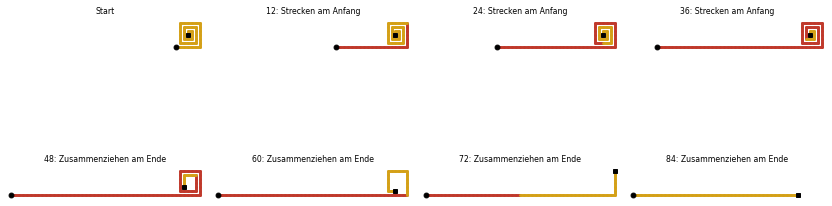

In [ ]:
def zeige_film(z, anzahl=8):
    """Zeigt `anzahl` gleichmäßig verteilte Bilder des Ablaufs (das erste und das letzte immer)."""
    b = z['bilder']
    auswahl = [round(k * (len(b) - 1) / (anzahl - 1)) for k in range(anzahl)]
    zeige_bilder([b[k] for k in auswahl])


def pruefe_ergebnis(z, n):
    """Wirft einen Fehler, wenn die Schlange nicht gerade, golden und n Ringel lang ist."""
    p, f = z['p'], z['f']
    assert len(f) == n and f == ['g'] * n, 'nicht golden oder falsche Länge'
    assert len(set(p)) == len(p) and all(nachbar(p[k], p[k + 1]) for k in range(n)), 'keine gültige Schlange'
    xs, ys = {q[0] for q in p}, {q[1] for q in p}
    assert len(xs) == 1 or len(ys) == 1, 'nicht gerade'


spirale = lies_schlange('eigene_testdaten/spirale.txt')
z = neuer_zustand(spirale)
print('Außen:', finde_aussen(z))
ziehe_gerade(z, *finde_aussen(z))
pruefe_ergebnis(z, len(spirale) - 1)
print(z['zaehler'], 'Endpunkte:', z['p'][0], z['p'][-1])
zeige_film(z)

Die Spirale (Bild 0) wird an der äußeren Spitze herausgestreckt (rot, bis zu `2n` Ringel), dann zieht sich das innere Ende durch die Spirale zurück. Am Ende liegen alle 42 Ringel golden auf einer Geraden. Dass die Zahl der Tauschschritte mit Abstand die größte ist, sehen wir weiter unten.

## Schritt 6: Fall 2 – beide Enden im Knäuel

`ecke_ganz_aussen` liefert die Ecke `Q`, die in Richtung `r` am weitesten außen liegt, bei Gleichstand die am weitesten „oben“ (`u` ist `r`, um 90 Grad nach links gedreht). Dann sind die beiden Nachbarn von `Q` links davon (`Q - r`) und darunter (`Q - u`), denn weiter außen oder höher liegt nichts.

In `ziehe_ecke_nach_aussen` wird `Q` `d`-mal ausgebuchtet. Die Nachbarn `a` und `c` von `Q` stehen in der Schlange entweder in der Reihenfolge links, `Q`, unten oder umgekehrt. Die drei neuen Punkte sind jeweils `Q`, `Q + r` und der Nachbar unten `+ r` (in der passenden Reihenfolge). `Q + r` ist danach die neue äußerste Ecke mit den gleichen Nachbarn, also wiederholt sich der Schritt.

In [ ]:
def ecke_ganz_aussen(punkte, r):
    """Der Punkt Q, der in Richtung r am weitesten außen liegt; bei mehreren der am weitesten 'oben'
    (u = r um 90 Grad nach links gedreht). Gibt (Q, u) zurück."""
    u = (-r[1], r[0])
    bester, beste_wertung = None, None
    for q in punkte:
        wertung = (q[0] * r[0] + q[1] * r[1], q[0] * u[0] + q[1] * u[1])      # Tupel werden der Reihe nach verglichen
        if beste_wertung is None or wertung > beste_wertung:
            bester, beste_wertung = q, wertung
    return bester, u


def abstand_zur_spitze(z, r):
    """Wie viele Ringel liegen zwischen der äußersten Ecke (Richtung r) und der näheren Spitze?"""
    q, u = ecke_ganz_aussen(z['p'], r)
    i = z['p'].index(q)
    return min(i, len(z['f']) - i)


def plus(a, b):
    return (a[0] + b[0], a[1] + b[1])


def minus(a, b):
    return (a[0] - b[0], a[1] - b[1])


def ziehe_ecke_nach_aussen(z, r):
    """Fall 2: Q d-mal ausbuchten (d = Abstand zur nächsten Spitze), dann die Spitze 2d-mal zusammenziehen."""
    p = z['p']
    q, u = ecke_ganz_aussen(p, r)
    i = p.index(q)
    if i > len(z['f']) - i:                                   # die nähere Spitze soll der Anfang sein
        p.reverse()                                           # nur umbenennen: Anfang und Ende tauschen die Rollen
        z['f'].reverse()
        i = len(z['f']) - i
    d = i
    for _ in range(d):
        i = p.index(q)
        a, c = p[i - 1], p[i + 1]
        if a == minus(q, r) and c == minus(q, u):             # Reihenfolge: links, Q, unten
            neu = [q, plus(q, r), plus(c, r)]
        elif a == minus(q, u) and c == minus(q, r):           # Reihenfolge: unten, Q, links
            neu = [plus(a, r), plus(q, r), q]
        else:
            raise ValueError('Ecke hat unerwartete Nachbarn')
        buchte_aus(z, i - 1, neu)
        q = plus(q, r)                                        # die neue äußerste Ecke
    for _ in range(2 * d):
        ziehe_zusammen_ende(z, 'a')
    return d

## Schritt 7: Alles zusammen

`entknaeule` prüft, ob eine Spitze außen liegt. Wenn nicht, wählt es unter den vier Richtungen die mit dem kleinsten Abstand `d` zur Spitze, macht eine Spitze zur äußeren (Fall 2) und streckt dann gerade (Fall 1).

{'Strecken': 17, 'Zusammenziehen': 19, 'Tauschen': 436} Bilder: 37


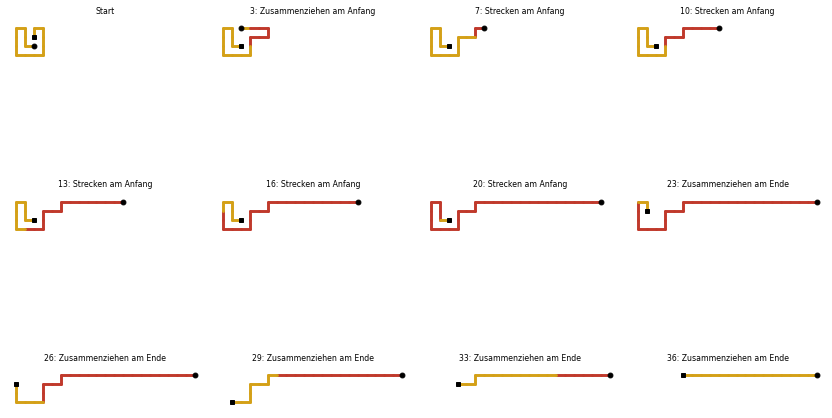

In [ ]:
def entknaeule(punkte):
    """Entknäult die Schlange; gibt den Zustand (mit Zählern und Bildern) zurück."""
    z = neuer_zustand(punkte)
    aussen = finde_aussen(z)
    if aussen is None:
        r = SCHRITT[0]
        for kandidat in SCHRITT:
            if abstand_zur_spitze(z, kandidat) < abstand_zur_spitze(z, r):
                r = kandidat
        ziehe_ecke_nach_aussen(z, r)
        aussen = finde_aussen(z)
    seite, r = aussen
    ziehe_gerade(z, seite, r)
    pruefe_ergebnis(z, len(punkte) - 1)
    return z


z = entknaeule(knaeuel)
print(z['zaehler'], 'Bilder:', len(z['bilder']))
zeige_film(z, 12)

Im kleinen 4x4-Knäuel sieht man die zwei Phasen:
- In den ersten Bildern wird eine Ecke Schritt für Schritt nach außen geschoben (rote Ausbuchtung) und das nähere Ende zieht sich zurück, bis dieses Ende ganz außen liegt.
- Danach wird dieses Ende gerade herausgestreckt und das andere Ende zieht sich aus dem Knäuel zurück. Am Ende liegt die Schlange gerade und golden.

## Schritt 8: Alle Beispiele und Kontrolle

Wir entknäulen alle vier Dateien und prüfen dabei bei **jedem** gemerkten Bild nach: Der Weg ist eine gültige Schlange (Nachbarpunkte, kein Punkt doppelt), die Länge ist nie kleiner als `n` und nie größer als `2n`, und die „Masse“ (2 je goldenes plus 1 je rotes Ringel) ist immer `2n`.

In [ ]:
def pruefe_bilder(z, n):
    for (_, p, f) in z['bilder']:
        assert len(p) == len(f) + 1 and len(set(p)) == len(p)
        assert all(nachbar(p[k], p[k + 1]) for k in range(len(f)))
        assert n <= len(f) <= 2 * n
        assert 2 * f.count('g') + f.count('r') == 2 * n


print('Datei           Ringel  Fall  Strecken  Zusammenz.  Tauschen   gesamt')
ergebnisse = {}
for name in ['spirale', 'knaeuel_4x4', 'knaeuel_6x6', 'knaeuel_8x8']:
    schlange = lies_schlange('eigene_testdaten/' + name + '.txt')
    n = len(schlange) - 1
    fall = 1 if finde_aussen(neuer_zustand(schlange)) else 2
    z = entknaeule(schlange)
    pruefe_bilder(z, n)
    c = z['zaehler']
    gesamt = c['Strecken'] + c['Zusammenziehen'] + c['Tauschen']
    ergebnisse[name] = (n, fall, c['Strecken'], c['Zusammenziehen'], c['Tauschen'], gesamt)
    print(f'{name:15} {n:6} {fall:5} {c["Strecken"]:9} {c["Zusammenziehen"]:11} {c["Tauschen"]:9} {gesamt:8}')

Datei           Ringel  Fall  Strecken  Zusammenz.  Tauschen   gesamt
spirale             42     1        42          42      3444     3528
knaeuel_4x4         15     2        17          19       436      472
knaeuel_6x6         35     2        38          41      2422     2501
knaeuel_8x8         63     2        69          75      8004     8148


Alle vier Schlangen enden gerade und golden (`pruefe_ergebnis` in `entknaeule` hätte sonst einen Fehler gemeldet). Die Spirale braucht nur Fall 1: `n` Strecken und `n` Zusammenziehen. Bei den Knäueln kommen die Ausbuchtungen und das Zurückziehen hinzu.

**Der Aufwand.** Die Hinweise schätzen für Fall 1 höchstens `2n(n + 2)` Schritte ab, fast alle davon Tauschen. Unsere Zahlen liegen knapp darunter (zwischen 92 % und 99,5 % der Schranke, siehe unten): Die Anzahl der Schritte wächst etwa mit `2n²`, wir sind also nicht besser als die Abschätzung der Hinweise. Das kommt vom Tauschen: Beim Strecken sitzen die goldenen Ringel mitten in der Schlange und müssen bis ans Ende wandern, beim Zusammenziehen die roten.

In [ ]:
for name, (n, fall, s, zz, t, gesamt) in ergebnisse.items():
    print(f'{name:12} n = {n:2}: gesamt {gesamt:5}, Schranke 2n(n+2) = {2 * n * (n + 2):5}, gesamt/n² = {gesamt / n ** 2:.2f}')

spirale      n = 42: gesamt  3528, Schranke 2n(n+2) =  3696, gesamt/n² = 2.00
knaeuel_4x4  n = 15: gesamt   472, Schranke 2n(n+2) =   510, gesamt/n² = 2.10
knaeuel_6x6  n = 35: gesamt  2501, Schranke 2n(n+2) =  2590, gesamt/n² = 2.04
knaeuel_8x8  n = 63: gesamt  8148, Schranke 2n(n+2) =  8190, gesamt/n² = 2.05


## Für Neugierige

- **Weniger tauschen:** Fast alle Schritte sind Farbentausch. Besser wäre, die roten und goldenen Ringel so zu ordnen, dass die Ringel, die als Nächstes gebraucht werden, schon am richtigen Ende liegen. Die Hinweise sagen, ein Greedy-Verfahren wie unseres reiche aus.
- **Kürzere Ausbuchtungen:** Die Hinweise wählen die äußerste Ecke, die am nächsten an einem Ende liegt, und buchten nur so oft aus, wie nötig. Wir nehmen von den vier Richtungen die mit dem kleinsten `d`.
- **Ein echter Film:** Mit `matplotlib.animation.FuncAnimation` lassen sich die gemerkten Bilder in `z['bilder']` als Animation abspielen. Die Bilder sind dafür schon vorbereitet.
- **Andere Darstellung:** Man kann die Schlange auch als Anfangspunkt plus Richtungen speichern (das Eingabeformat unserer Dateien). Der Vorteil sind kleinere Daten, der Nachteil: Beim Ausbuchten ändern sich viele Richtungen, und für „ist der Punkt frei?“ braucht man ohnehin die Punkte.

## Zum Schluss: Warum hier kein MiniZinc?

MiniZinc passt gut zu Aufgaben, bei denen man **eine** Belegung von Variablen sucht (Summen, Zuordnungen, Permutationen). Hier suchen wir eine **Folge von Schritten** unbekannter Länge, bei der sich nach jedem Schritt die ganze Schlange ändert. Man müsste für jeden Zeitpunkt die komplette Punkt- und Farbliste als Variablen anlegen und die Schrittregeln als Nebenbedingungen zwischen zwei Zeitpunkten schreiben, und die Länge der Folge vorgeben. Schon beim 4x4-Knäuel braucht unser Verfahren rund 470 Schritte, fast alle davon Farbentausch. Bei ähnlichen Aufgaben mit Folgen von Zügen (ChoreoGraph) waren die Solver dafür ungeeignet. Außerdem gibt es keine Beispieldaten der Aufgabe, an denen man Laufzeiten messen könnte. Deshalb haben wir das Verfahren nur in Python umgesetzt.